# A tour of `bonsai`

[*Bonsai*](https://doi.org/10.1101/2025.05.08.652944) (de Groot, Morillo Leonardo, Pachkov, van
Nimwegen) reconstructs a Bayesian maximum-likelihood cell tree from per-cell, per-gene expression
estimates with error bars. This package (`mlbelab/bonsai`) wraps the original upstream algorithm
(unchanged — see [`../deviations.md`](../deviations.md) and [`../provenance.md`](../provenance.md))
behind a small `AnnData`-based API: `bonsai.pp` for preprocessing/input, `bonsai.tl.reconstruct`
for the tree search, and `bonsai.io` for reading result folders.

This notebook tours that API on five example datasets, from a tiny simulated tree to three real
scRNA-seq datasets preprocessed with [*Sanity*](https://github.com/jmbreda/Sanity) (Breda, Zavolan
& van Nimwegen, 2021): a brain-organoid neuroepithelium dataset, an intestinal-organoid EEC
differentiation dataset, and the control cells of a CRISPR-perturbation intestinal-organoid atlas.

**Reproducing this notebook**

- The two simulated datasets run from files already committed to the repo.
- The three real-data sections each need their own *Sanity* output and reconstruction cached in a
  workspace data folder (`DATA_DIR` below, outside this repo — see
  `docs/notebooks/prepare_organoid_data.py` and `docs/notebooks/prepare_perturb_ctrl_data.py` for
  exactly how each was produced, and the *Sanity* command used). If a folder is not found, that
  section is skipped with a note, and the rest of the notebook still runs.
- Set `RERUN = True` below to redo the *Bonsai* reconstructions instead of loading the cached
  results (the two small examples are fast; the organoid searches are the long steps, see the
  runtime table at the end). A rerun writes to a fresh work directory rather than overwriting the
  cached one.


In [1]:
import contextlib
import io
import os
from pathlib import Path

import anndata as ad

import bonsai

REPO_ROOT = Path.cwd().parent.parent if (Path.cwd().name == "notebooks") else Path.cwd()
# Workspace data folder, outside the git repo (never committed): `../data` relative to the repo
# root by default, overridable with BONSAI_DATA_DIR for other layouts.
DATA_DIR = Path(os.environ.get("BONSAI_DATA_DIR", REPO_ROOT.parent / "data"))
BRAIN_DIR = DATA_DIR / "fleck_neuroepithelium_sub"
EEC_DIR = DATA_DIR / "eec_vasa_sub"
PERTURB_DIR = DATA_DIR / "perturb_ctrl_sub"

RERUN = False  # set True to redo the Bonsai reconstructions instead of loading cached results


def relative(path):
    """Render `path` relative to `REPO_ROOT` for display, without baking an absolute user path into committed output."""
    try:
        return str(Path(path).resolve().relative_to(REPO_ROOT.resolve()))
    except ValueError:
        return f"../{Path(path).name}"


def reconstruct_quietly(*args, **kwargs):
    """Run `bonsai.tl.reconstruct`, swallowing upstream's one-line mpi4py-not-installed notice."""
    with contextlib.redirect_stdout(io.StringIO()):
        return bonsai.tl.reconstruct(*args, **kwargs)


print("workspace data dir:", relative(DATA_DIR), "(exists:", DATA_DIR.exists(), ")")

workspace data dir: ../data (exists: True )


## 1. A 64-cell simulated binary tree

Upstream's own test fixture: a 64-cell binary tree simulated over 6 generations of left/right
splits, with sampling noise added (legacy *Sanity* `_vmax` output format, read transparently by
`bonsai.pp.read_sanity`). Cell names encode the true lineage path, e.g. `Cell010111` took the
sequence left(0)-right(1)-right-right-right-right. We reconstruct with a small random-tree search
budget (`nnn_n_randommoves=10, nnn_n_randomtrees=2`, matching the repo's own fast golden-test
config) since this is an illustration, not a convergence study.

**On rooting**: *Bonsai* places its root by a display convention (`set_mindist_root`, falling back
to a midpoint root) — the reconstruction likelihood does not depend on where the root sits. Tree
plots below show that chosen root, but any metric that depends on absolute root placement (rather
than on splits/distances, which are root-independent) should be read as illustrative only.


In [2]:
import time

FIXTURE_64 = REPO_ROOT / "tests" / "data" / "simulated_binary_6_gens_samplingNoise"
adata_64 = bonsai.pp.read_sanity(FIXTURE_64)
print(adata_64)

t0 = time.time()
reconstruct_quietly(adata_64, nnn_n_randommoves=10, nnn_n_randomtrees=2, verbose=False)
time_64 = time.time() - t0
print(
    f"reconstructed in {time_64:.1f}s, loglik={adata_64.uns['bonsai']['loglik']:.1f}, "
    f"{adata_64.var['bonsai_used'].sum()} genes used"
)

AnnData object with n_obs × n_vars = 64 × 12304
    var: 'bonsai_prior_var', 'bonsai_mu'
    uns: 'bonsai_input'
    layers: 'bonsai_mean', 'bonsai_sd'


reconstructed in 52.3s, loglik=-65745.7, 1131 genes used


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def tree_topology(edges, nodes):
    """Return `children`: {parent_vertInd: [(child_vertInd, branch_len), ...]}, and the root vertInd."""
    children, parent_of = {}, {}
    for _, row in edges.iterrows():
        p, c, t = int(row["parent"]), int(row["child"]), float(row["t"])
        children.setdefault(p, []).append((c, t))
        parent_of[c] = p
    root = next(i for i in set(nodes["vertInd"]) if i not in parent_of)
    return children, root


def subtree_sizes(children, root):
    """Return {vertInd: number of descendant leaves}, used to ladderise the plotted leaf order."""
    sizes = {}

    def rec(i):
        if i not in children:
            sizes[i] = 1
            return 1
        sizes[i] = sum(rec(c) for c, _ in children[i])
        return sizes[i]

    rec(root)
    return sizes


def plot_tree(edges, nodes, leaf_color=None, cmap=None, continuous=False, ax=None, legend_title="group"):
    """Rectangular tree plot: x = cumulative branch length from the root, y = ladderised leaf order.

    `edges`/`nodes` are the DataFrames in `adata.uns["bonsai"]`. `leaf_color` is an optional
    {cell name: value} mapping used to colour the leaf markers (categorical, or continuous with
    `continuous=True`, using a sequential `viridis` colormap by default). Leaves are ladderised: at
    each internal node, the smaller-subtree child is drawn first.
    """
    cmap = cmap or ("viridis" if continuous else "tab10")
    children, root = tree_topology(edges, nodes)
    name_of = nodes.set_index("vertInd")["name"]
    sizes = subtree_sizes(children, root)

    depth = {root: 0.0}
    order = [root]
    i = 0
    while i < len(order):
        p = order[i]
        i += 1
        for c, t in children.get(p, []):
            depth[c] = depth[p] + t
            order.append(c)

    def leaf_order(i):
        if i not in children:
            return [i]
        out = []
        for c, _ in sorted(children[i], key=lambda ct: sizes[ct[0]]):
            out.extend(leaf_order(c))
        return out

    ordered_leaves = leaf_order(root)
    y = {leaf: pos for pos, leaf in enumerate(ordered_leaves)}

    def internal_y(i):
        if i in y:
            return y[i]
        y[i] = float(np.mean([internal_y(c) for c, _ in children[i]]))
        return y[i]

    internal_y(root)

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5), dpi=100)
    for p, kids in children.items():
        for c, _ in kids:
            ax.plot([depth[p], depth[p]], [y[p], y[c]], color="0.3", lw=0.6)
            ax.plot([depth[p], depth[c]], [y[c], y[c]], color="0.3", lw=0.6)

    if leaf_color is not None:
        names = [name_of[i] for i in ordered_leaves]
        vals = [leaf_color.get(n) for n in names]
        xs = [depth[i] for i in ordered_leaves]
        ys = [y[i] for i in ordered_leaves]
        if continuous:
            sc = ax.scatter(xs, ys, c=vals, cmap=cmap, s=10, zorder=3)
            plt.colorbar(sc, ax=ax, shrink=0.6, label=legend_title)
        else:
            cats = sorted({v for v in vals if pd.notna(v)}, key=str)
            palette = plt.get_cmap(cmap)
            cmap_map = {c: palette(i / max(1, len(cats) - 1)) for i, c in enumerate(cats)}
            colors = [cmap_map.get(v, (0.8, 0.8, 0.8, 1.0)) for v in vals]
            ax.scatter(xs, ys, c=colors, s=10, zorder=3)
            handles = [
                plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=cmap_map[c], label=str(c)) for c in cats
            ]
            ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=7, title=legend_title)
    ax.set_xlabel("cumulative branch length from root")
    ax.set_yticks([])
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    return ax

We colour the leaves by the first bit, first two bits, and first three bits of each cell's
simulated lineage path (`CellBBBBBB` -> `B` = 0/1 choice per generation), which should separate
into increasingly fine, nested clades.


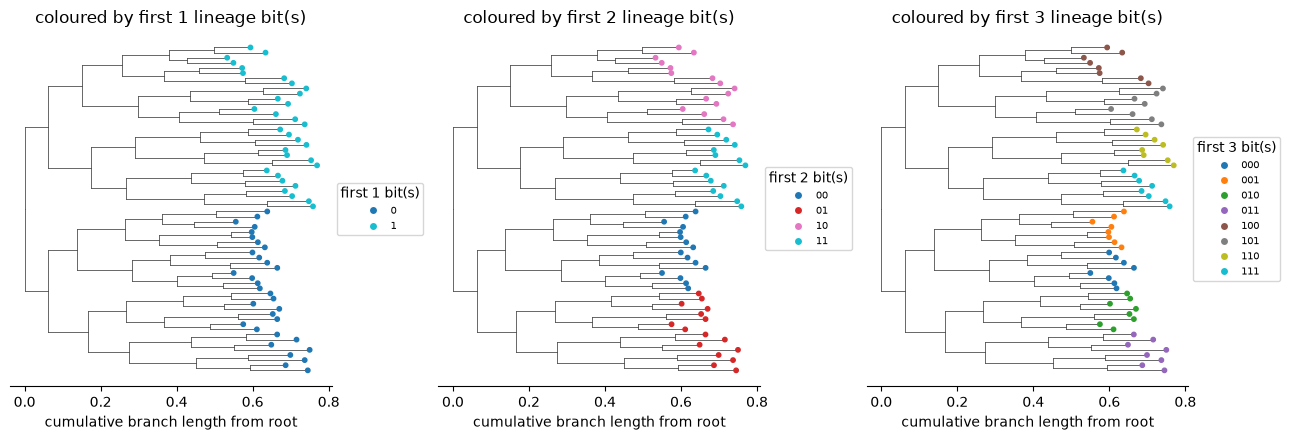

In [4]:
def lineage_bits(name, n):
    """First `n` characters of a `CellBBBBBB`-style name's lineage path (its generation-1..n choices)."""
    return name.replace("Cell", "")[:n]


fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), dpi=100)
edges, nodes = adata_64.uns["bonsai"]["edges"], adata_64.uns["bonsai"]["nodes"]
for ax, n in zip(axes, (1, 2, 3), strict=True):
    colors = {name: lineage_bits(name, n) for name in adata_64.obs_names}
    plot_tree(edges, nodes, leaf_color=colors, ax=ax, legend_title=f"first {n} bit(s)")
    ax.set_title(f"coloured by first {n} lineage bit(s)")
fig.tight_layout()
plt.show()

**Split recovery**: *Bonsai*'s root is a display convention (see above), so we compare trees as
*unrooted* splits rather than rooted clades. Every true clade implied by the lineage tree (every
prefix of the lineage string defines a clade — all cells sharing that prefix) induces a
bipartition of all 64 leaves (the clade vs. everything else). We count a true clade as recovered if
*either side* of that bipartition appears as the descendant-leaf-set of some node in the
reconstructed tree — removing any edge of a rooted binary tree exposes exactly one bipartition of
the full unrooted tree, regardless of where the root happens to sit.


In [5]:
def leaf_descendants(children, root):
    """Return {vertInd: frozenset of descendant leaf ids}, one side of the split at every edge."""
    out = {}

    def rec(i):
        if i not in children:
            out[i] = frozenset({i})
            return out[i]
        out[i] = frozenset().union(*(rec(c) for c, _ in children[i]))
        return out[i]

    rec(root)
    return out


def split_recovery(true_clades, edges, nodes):
    """Fraction of `true_clades` whose bipartition (clade vs. complement) matches a reconstructed split."""
    children, root = tree_topology(edges, nodes)
    name_of = nodes.set_index("vertInd")["name"]
    all_leaves = frozenset(name_of[i] for i in leaf_descendants(children, root)[root])
    desc = leaf_descendants(children, root)
    recon_sides = {frozenset(name_of[i] for i in leafset) for leafset in desc.values()}
    hits = 0
    for c in true_clades:
        side_a = frozenset(c)
        side_b = all_leaves - side_a
        if side_a in recon_sides or side_b in recon_sides:
            hits += 1
    return hits / len(true_clades)


names = list(adata_64.obs_names)
true_clades = []
for n in range(1, 7):
    prefixes = {lineage_bits(name, n) for name in names}
    for p in prefixes:
        true_clades.append({name for name in names if lineage_bits(name, n) == p})

recovery_64 = split_recovery(true_clades, edges, nodes)
print(f"split recovery: {recovery_64:.1%} of {len(true_clades)} true clades (generations 1-6)")

split recovery: 100.0% of 126 true clades (generations 1-6)


## 2. An in-notebook simulator (~300 cells, likelihood input)

For data that is not *Sanity* output (e.g. per-cell state estimates from another pipeline),
`bonsai.pp.from_arrays` marks a mean (and optional SD) layer as a likelihood input directly — no
Sanity step needed. Here we fabricate ~300 cells by simulating a random binary tree with
exponential branch lengths, propagating Brownian diffusion down the tree in G~500 dimensions, and
adding heteroscedastic per-cell/gene observation noise. As in §1, reconstruction uses a reduced
random-tree search budget (`nnn_n_randommoves=50, nnn_n_randomtrees=3`, vs. the function defaults
of 1000/10) to keep runtime reasonable for this illustration.


In [6]:
def simulate_binary_tree(n_leaves, n_genes, seed=0):
    """Random bifurcating tree (exponential branch lengths) with Brownian-motion leaf states.

    Returns (noisy per-cell observations, per-cell/gene SDs, true edges, true nodes), the last two
    in the same (parent, child, t) / (vertInd, name) shape as `adata.uns["bonsai"]`.
    """
    rng = np.random.default_rng(seed)
    next_id = n_leaves
    edges_sim = []  # (parent, child, t), vertInd-like ids
    active = list(range(n_leaves))
    while len(active) > 1:
        i, j = rng.choice(len(active), size=2, replace=False)
        a, b = active[i], active[j]
        parent = next_id
        next_id += 1
        edges_sim.append((parent, a, rng.exponential(0.3)))
        edges_sim.append((parent, b, rng.exponential(0.3)))
        active = [x for k, x in enumerate(active) if k not in (i, j)] + [parent]
    root = active[0]

    children = {}
    for p, c, t in edges_sim:
        children.setdefault(p, []).append((c, t))

    value = {root: np.zeros(n_genes)}
    order = [root]
    i = 0
    while i < len(order):
        p = order[i]
        i += 1
        for c, t in children.get(p, []):
            value[c] = value[p] + rng.normal(0, np.sqrt(t), size=n_genes)
            order.append(c)

    true_mean = np.array([value[i] for i in range(n_leaves)])
    sds = rng.uniform(0.1, 0.5, size=(n_leaves, n_genes))
    obs = true_mean + rng.normal(size=(n_leaves, n_genes)) * sds
    true_edges = pd.DataFrame(edges_sim, columns=["parent", "child", "t"])
    true_nodes = pd.DataFrame(
        {
            "vertInd": list(range(next_id)),
            "name": [f"leaf{i}" for i in range(n_leaves)] + [f"internal{i}" for i in range(n_leaves, next_id)],
        }
    )
    return obs, sds, true_edges, true_nodes


N_LEAVES, N_GENES = 300, 500
obs, sds, true_edges, true_nodes = simulate_binary_tree(N_LEAVES, N_GENES, seed=0)

adata_sim = ad.AnnData(
    X=obs,
    obs=pd.DataFrame(index=[f"leaf{i}" for i in range(N_LEAVES)]),
    var=pd.DataFrame(index=[f"gene{i}" for i in range(N_GENES)]),
)
adata_sim.layers["mean"] = obs
adata_sim.layers["sd"] = sds
bonsai.pp.from_arrays(adata_sim, mean_layer="mean", sd_layer="sd")

t0 = time.time()
reconstruct_quietly(adata_sim, nnn_n_randommoves=50, nnn_n_randomtrees=3, verbose=False)
time_sim = time.time() - t0
print(f"reconstructed {N_LEAVES} cells in {time_sim:.1f}s, loglik={adata_sim.uns['bonsai']['loglik']:.1f}")

reconstructed 300 cells in 320.8s, loglik=21084.1


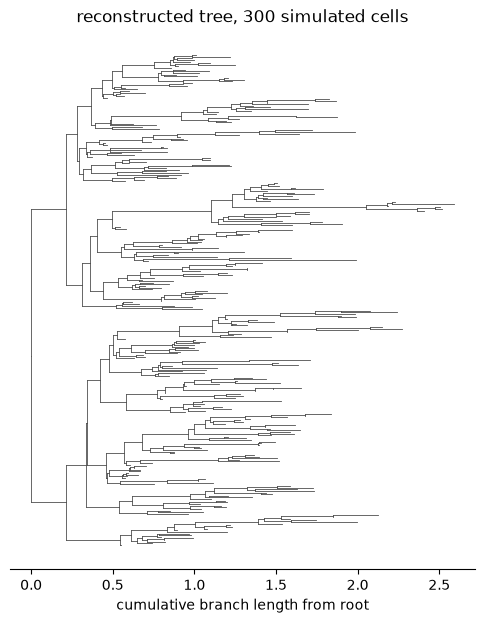

In [7]:
fig, ax = plt.subplots(figsize=(6, 7), dpi=100)
plot_tree(adata_sim.uns["bonsai"]["edges"], adata_sim.uns["bonsai"]["nodes"], ax=ax)
ax.set_title(f"reconstructed tree, {N_LEAVES} simulated cells")
plt.show()

**Quartet accuracy**: for random quartets of leaves, does the reconstructed tree agree with the
true simulated tree on which pair is the "closest" pair (i.e. on the `ab|cd`-style unrooted
quartet topology)? Unlike rooted clade/triplet statistics, a quartet topology is a property of the
unrooted tree, so it does not depend on *Bonsai*'s display-convention root. A quartet is
*unresolved* when the four leaves meet at a single polytomy (no internal edge separates any pair
from the other two) — in this reconstructed tree, which is a strictly bifurcating binary tree,
that cannot happen, but we check for it anyway since real reconstructions can carry polytomies.


In [8]:
def leaf_paths_from_root(children, root):
    """Return {vertInd: [root, ..., vertInd]}, the ancestor chain of every node from the root."""
    paths = {}

    def rec(i, path):
        path = path + [i]
        if i not in children:
            paths[i] = path
        else:
            for c, _ in children[i]:
                rec(c, path)

    rec(root, [])
    return paths


def pairwise_topo_distance(a, b, paths):
    """Number of edges between leaves `a` and `b`, via their shared root-to-leaf path prefix (root-independent)."""
    pa, pb = paths[a], paths[b]
    shared = 0
    for x, y in zip(pa, pb, strict=False):  # paths may differ in length; stop at first divergence
        if x != y:
            break
        shared += 1
    return (len(pa) - shared) + (len(pb) - shared)


def quartet_topology(quartet, paths):
    """Resolve a 4-leaf quartet from pairwise topological distances (four-point condition).

    Returns the sister pair as a `frozenset`, or `None` if the quartet is unresolved (a polytomy:
    all three pairings give the same total path length).
    """
    a, b, c, d = quartet
    pairings = {
        frozenset({a, b}): pairwise_topo_distance(a, b, paths) + pairwise_topo_distance(c, d, paths),
        frozenset({a, c}): pairwise_topo_distance(a, c, paths) + pairwise_topo_distance(b, d, paths),
        frozenset({a, d}): pairwise_topo_distance(a, d, paths) + pairwise_topo_distance(b, c, paths),
    }
    best = min(pairings.values())
    winners = [pair for pair, total in pairings.items() if total == best]
    return winners[0] if len(winners) == 1 else None


def quartet_accuracy(true_edges, true_nodes, recon_edges, recon_nodes, leaf_names, n_quartets=2000, seed=0):
    """Fraction of random quartets resolved identically by the true and reconstructed trees.

    Returns (accuracy among resolved-in-both quartets, fraction of quartets unresolved in either tree).
    """
    rng = np.random.default_rng(seed)
    ch_t, root_t = tree_topology(true_edges, true_nodes)
    ch_r, root_r = tree_topology(recon_edges, recon_nodes)
    name_t = true_nodes.set_index("vertInd")["name"]
    name_r = recon_nodes.set_index("vertInd")["name"]
    paths_t = {name_t[i]: p for i, p in leaf_paths_from_root(ch_t, root_t).items()}
    paths_r = {name_r[i]: p for i, p in leaf_paths_from_root(ch_r, root_r).items()}
    names = list(leaf_names)
    correct, unresolved, total = 0, 0, 0
    for _ in range(n_quartets):
        quartet = rng.choice(names, size=4, replace=False)
        top_t = quartet_topology(quartet, paths_t)
        top_r = quartet_topology(quartet, paths_r)
        total += 1
        if top_t is None or top_r is None:
            unresolved += 1
            continue
        correct += int(top_t == top_r)
    resolved = total - unresolved
    return (correct / resolved if resolved else float("nan")), unresolved / total


acc_sim, unresolved_frac = quartet_accuracy(
    true_edges,
    true_nodes,
    adata_sim.uns["bonsai"]["edges"],
    adata_sim.uns["bonsai"]["nodes"],
    adata_sim.obs_names,
    n_quartets=2000,
)
print(f"quartet accuracy: {acc_sim:.1%} (2000 random quartets, {unresolved_frac:.1%} unresolved)")

quartet accuracy: 100.0% (2000 random quartets, 0.0% unresolved)


### Tree distance vs. expression distance (simulator)

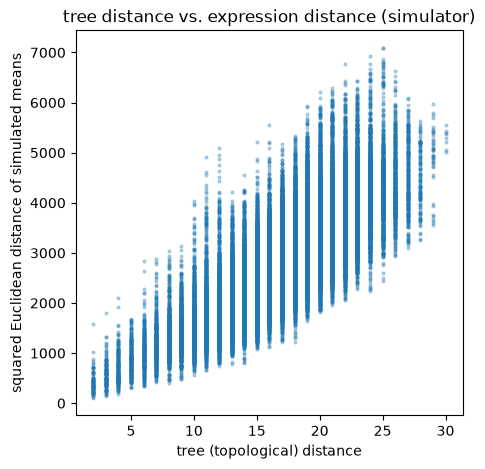

In [9]:
from scipy.spatial.distance import pdist, squareform


def cophenetic_matrix(leaf_names, children, root, name_to_vert):
    """Pairwise topological (path-length) distance matrix between `leaf_names`, root-independent."""
    paths = leaf_paths_from_root(children, root)
    verts = [name_to_vert[name] for name in leaf_names]
    n = len(verts)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            d = pairwise_topo_distance(verts[i], verts[j], paths)
            D[i, j] = D[j, i] = d
    return D


children_sim, root_sim = tree_topology(adata_sim.uns["bonsai"]["edges"], adata_sim.uns["bonsai"]["nodes"])
vert_of_name_sim = adata_sim.uns["bonsai"]["nodes"].set_index("name")["vertInd"]
tree_dist_sim = squareform(cophenetic_matrix(list(adata_sim.obs_names), children_sim, root_sim, vert_of_name_sim))
# Squared Euclidean distance is linear in path length under Brownian motion (the simulator here),
# so we plot it directly rather than the (non-linear) Euclidean distance.
expr_dist_sim = pdist(adata_sim.layers["mean"], metric="sqeuclidean")

fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
ax.scatter(tree_dist_sim, expr_dist_sim, s=4, alpha=0.3)
ax.set_xlabel("tree (topological) distance")
ax.set_ylabel("squared Euclidean distance of simulated means")
ax.set_title("tree distance vs. expression distance (simulator)")
plt.show()

## 3. A real dataset: brain-organoid neuroepithelium (Sanity-processed)

[Fleck et al. 2022](https://doi.org/10.1038/s41586-022-05279-8) profiled human brain organoids
spanning neuroepithelium to regionalised neural tissue (days 15-26). We subsample 387 cells
stratified by `age` x `lineage` (fixed seed, `docs/notebooks/prepare_organoid_data.py`; about 22
cells are requested per stratum, with small strata under-filled), keep genes detected in >=10
sampled cells (13,222 genes), and preprocess the raw UMI counts with *Sanity* before handing them
to *Bonsai*.

**Preprocessing (outside this notebook, see `prepare_organoid_data.py`)**

```bash
python docs/notebooks/prepare_organoid_data.py <neuroepithelium.h5ad> <out_dir> --n-cells 500 --seed 0
```

This writes `counts.tsv` (genes x cells, tab-separated, as *Sanity*'s `-f` flag expects) and
`cell_meta.csv` (the sampled cells' annotations, for plotting here). *Sanity* is then run once,
**with the flags the package README requires** (`-e 1 -v_m MAP`):

```bash
Sanity -f counts.tsv -d sanity_out -n <threads> -e 1 -v_m MAP
```

This took about 2.5 minutes for 387 cells x 13,222 genes on a shared 2-core node (measured from
the first to the last timestamp in `sanity_out`'s run log); 626 of the 13,222 genes
survived *Bonsai*'s z-score filter (`var["bonsai_used"]`, printed below). The *Bonsai*
reconstruction below uses a reduced random-tree search budget
(`nnn_n_randommoves=20, nnn_n_randomtrees=2`, vs. the function defaults of 1000/10) to keep runtime
reasonable on such a node — see the runtime table at the end for exact numbers; this is purely a
computational shortcut and does not change what the algorithm optimises.


In [10]:
if not BRAIN_DIR.exists():
    print(f"brain-organoid inputs not found at {relative(BRAIN_DIR)}; skipping this section.")
    adata_brain = None
else:
    cached_h5ad = BRAIN_DIR / "adata_bonsai.h5ad"
    workdir = BRAIN_DIR / "bonsai_workdir"
    if not RERUN and cached_h5ad.exists():
        adata_brain = ad.read_h5ad(cached_h5ad)
        # Re-point at this session's workdir in case DATA_DIR moved since the cache was written,
        # but keep whichever subfolder name the cached run actually used (a rerun that hit a
        # non-empty `bonsai_workdir` gets a fresh `bonsai_workdir_<timestamp>` below, and loading
        # the cache later must follow that same folder, not silently fall back to the plain name).
        cached_workdir_name = Path(adata_brain.uns["bonsai"]["workdir"]).name
        workdir = BRAIN_DIR / cached_workdir_name
        assert workdir.exists(), f"cached workdir {workdir} is missing"
        adata_brain.uns["bonsai"]["workdir"] = str(workdir)
        time_brain = adata_brain.uns.get("bonsai_tour_seconds")
        print(f"loaded cached reconstruction: {adata_brain}")
    else:
        adata_brain = bonsai.pp.read_sanity(BRAIN_DIR / "sanity_out")
        cell_meta = pd.read_csv(BRAIN_DIR / "cell_meta.csv", index_col=0)
        adata_brain.obs = adata_brain.obs.join(cell_meta)
        if workdir.exists():
            # reconstruct() refuses a non-empty pre-existing workdir; a rerun gets a fresh one.
            workdir = BRAIN_DIR / f"bonsai_workdir_{int(time.time())}"
        t0 = time.time()
        reconstruct_quietly(
            adata_brain,
            nnn_n_randommoves=20,
            nnn_n_randomtrees=2,
            workdir=workdir,
            keep_workdir=True,
            verbose=False,
        )
        time_brain = time.time() - t0
        adata_brain.uns["bonsai_tour_seconds"] = time_brain
        print(f"reconstructed in {time_brain:.1f}s")
        adata_brain.write_h5ad(cached_h5ad)
    print(adata_brain)
    print(f"{adata_brain.var['bonsai_used'].sum()} genes used of {adata_brain.n_vars}")

loaded cached reconstruction: AnnData object with n_obs × n_vars = 387 × 13222
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'percent_mito', 'RNA.weight', 'ATAC.weight', 'wsnn_res.0.8', 'seurat_clusters', 'nCount_peaks', 'nFeature_peaks', 'dataset', 'demux_modality', 'line', 'best', 'p_singlet', 'demux_call', 'RNA_snn_res.0.8', 'organoid', 'age', 'nowakowski_prediction', 'RNA_snn_res.1', 'glyc_cluster', 'nepi', 'pseudocell', 'pseudotime_ranks', 'lineage', 'lineage_coarse', 'S.Score', 'G2M.Score', 'Phase', 'group', 'integrated_snn_res.0.8', 'lambda.1se', 'midbrain_prob_ridge', 'hindbrain_prob_ridge', 'forebrain_prob_ridge', 'predicted.id', 'prediction.score.Hindbrain', 'prediction.score.Forebrain', 'prediction.score.Midbrain', 'prediction.score.max', 'prediction.score.ventral', 'prediction.score.dorsal', 'DV_score_css', 'forebrain_prob_css', 'hindbrain_prob_css', 'midbrain_prob_css', 'ident', 'bonsai_node'
    var: 'bonsai_prior_var', 'bonsai_mu', 

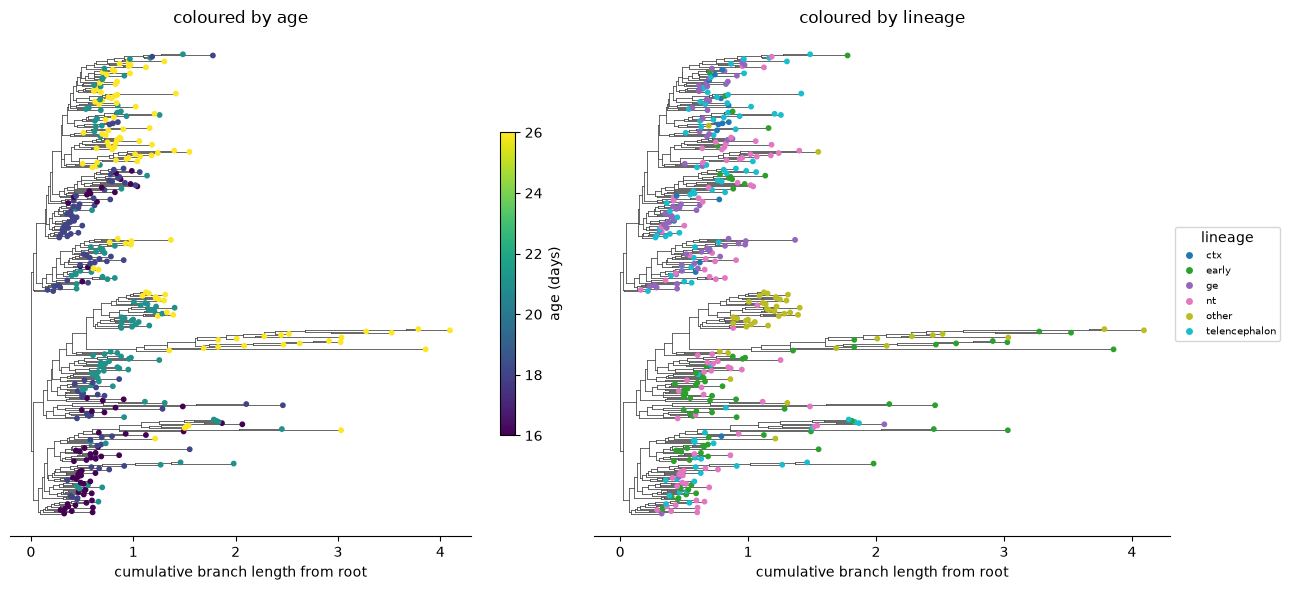

In [11]:
if adata_brain is not None:
    edges_b, nodes_b = adata_brain.uns["bonsai"]["edges"], adata_brain.uns["bonsai"]["nodes"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), dpi=100)
    age_colors = dict(zip(adata_brain.obs_names, adata_brain.obs["age"], strict=True))
    plot_tree(edges_b, nodes_b, leaf_color=age_colors, continuous=True, ax=axes[0], legend_title="age (days)")
    axes[0].set_title("coloured by age")
    lineage_colors = dict(zip(adata_brain.obs_names, adata_brain.obs["lineage"].astype(str), strict=True))
    plot_tree(edges_b, nodes_b, leaf_color=lineage_colors, ax=axes[1], legend_title="lineage")
    axes[1].set_title("coloured by lineage")
    fig.tight_layout()
    plt.show()

### Exploratory: distance from the most immature cells vs. pseudotime

Depth from *Bonsai*'s display-convention root is not a meaningful developmental axis by itself
(see the rooting note in §1). Instead we measure each cell's tree (topological) distance from the
cell with the *earliest* `pseudotime_ranks` in this subsample — a root-independent quantity — and
compare it to `pseudotime_ranks`. This is exploratory: a handful of reference cells, sampling noise
and the small subsample size all limit what can be concluded.


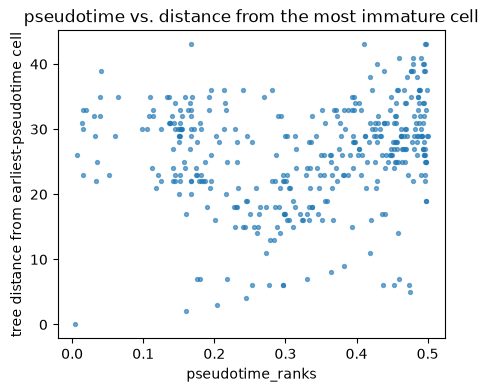

In [12]:
if adata_brain is not None:
    children_b, root_b = tree_topology(edges_b, nodes_b)
    vert_of_name = nodes_b.set_index("name")["vertInd"]
    paths_b = leaf_paths_from_root(children_b, root_b)

    pt = adata_brain.obs["pseudotime_ranks"]
    mask = pt.notna()
    reference_cell = pt.loc[mask].idxmin()  # earliest pseudotime cell in this subsample
    reference_vert = vert_of_name[reference_cell]
    dist_from_reference = [
        pairwise_topo_distance(reference_vert, vert_of_name[name], paths_b) for name in adata_brain.obs_names[mask]
    ]

    fig, ax = plt.subplots(figsize=(5, 4), dpi=100)
    ax.scatter(pt.loc[mask], dist_from_reference, s=8, alpha=0.6)
    ax.set_xlabel("pseudotime_ranks")
    ax.set_ylabel("tree distance from earliest-pseudotime cell")
    ax.set_title("pseudotime vs. distance from the most immature cell")
    plt.show()

### Gene painting

`bonsai.tl.node_posteriors` returns the posterior mean (and variance) of every used gene at every
node of the tree (needs `reconstruct(..., keep_workdir=True)`, as used above). The candidate panel
covers progenitor/radial-glia markers (SOX2, VIM, HES5), a neuronal marker (DCX), and regional
markers — FOXG1 (telencephalon), OTX2 (fore-/midbrain), LHX2 and RSPO3 (cortical hem / dorsal
telencephalon) — restricted to genes that survived the z-score filter (`var["bonsai_used"]`).


markers shown (present in bonsai_used): ['SOX2', 'VIM', 'HES5', 'DCX', 'FOXG1', 'OTX2', 'LHX2', 'RSPO3']


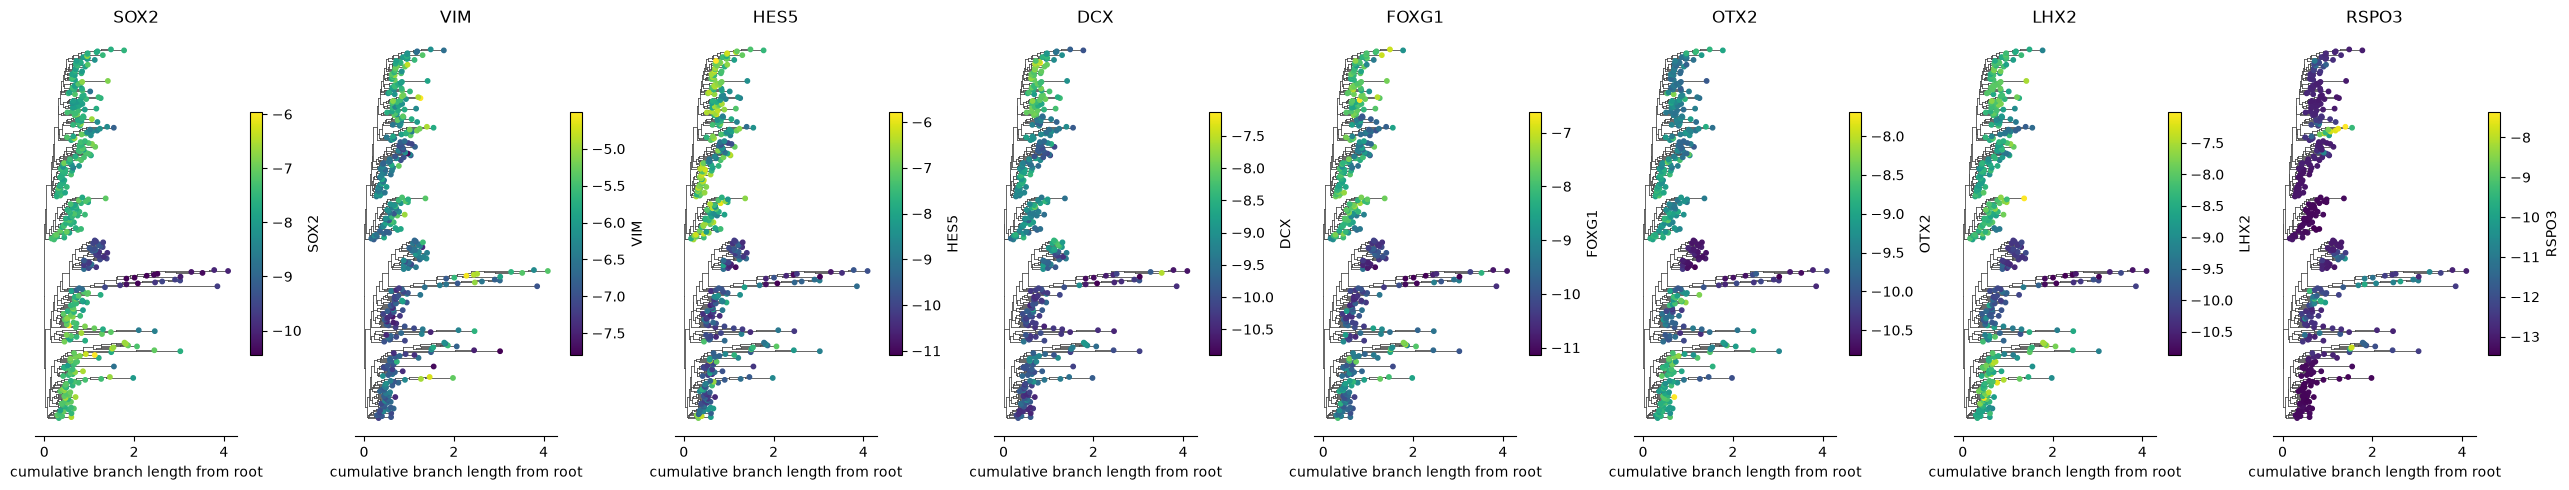

In [13]:
if adata_brain is not None:
    node_post = bonsai.tl.node_posteriors(adata_brain)
    candidate_markers = ["SOX2", "VIM", "HES5", "NEUROD6", "DCX", "FOXG1", "OTX2", "DLX2", "LHX2", "RSPO3"]
    markers = [g for g in candidate_markers if g in node_post.var_names]
    print("markers shown (present in bonsai_used):", markers)

    leaf_vert = {
        row["name"]: row["vertInd"] for _, row in nodes_b.iterrows() if row["name"] in set(adata_brain.obs_names)
    }
    fig, axes = plt.subplots(1, len(markers), figsize=(3.2 * len(markers), 5), dpi=100)
    for ax, gene in zip(np.atleast_1d(axes), markers, strict=True):
        vals_by_vert = dict(zip(node_post.obs["vertInd"], node_post[:, gene].X.ravel(), strict=True))
        leaf_color = {name: vals_by_vert[v] for name, v in leaf_vert.items()}
        plot_tree(edges_b, nodes_b, leaf_color=leaf_color, continuous=True, ax=ax, legend_title=gene)
        ax.set_title(gene)
    fig.tight_layout()
    plt.show()

### Heatmap of ~40 informative genes (cells in tree-leaf order)

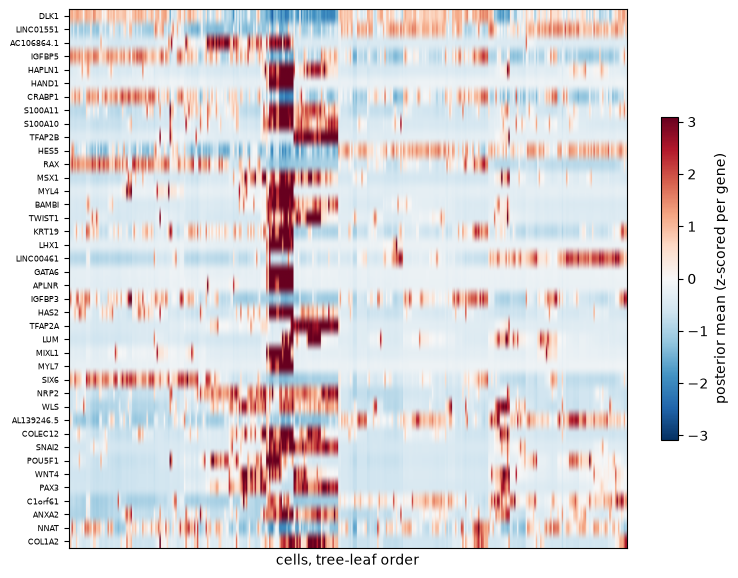

In [14]:
if adata_brain is not None:
    gene_var = node_post.X.var(axis=0)
    top_genes = node_post.var_names[np.argsort(gene_var)[::-1][:40]]

    def ladderised_leaf_order(i, children, sizes):
        """Ladderised leaf order below node `i` (smaller-subtree child first, matching `plot_tree`)."""
        if i not in children:
            return [i]
        out = []
        for c, _ in sorted(children[i], key=lambda ct: sizes[ct[0]]):
            out.extend(ladderised_leaf_order(c, children, sizes))
        return out

    sizes_b = subtree_sizes(children_b, root_b)
    ordered_vert = [v for v in ladderised_leaf_order(root_b, children_b, sizes_b) if v in set(leaf_vert.values())]
    vert_to_name = nodes_b.set_index("vertInd")["name"]
    ordered_names = [vert_to_name[v] for v in ordered_vert]

    leaf_node_post = node_post[node_post.obs["vertInd"].isin(leaf_vert.values())]
    leaf_node_post = leaf_node_post[[n for n in ordered_names if n in leaf_node_post.obs_names]]
    raw = leaf_node_post[:, top_genes].X.T
    # Posterior means are log-transcription-quotients (large, gene-specific baselines), so
    # z-score each gene across cells to show relative up/down regulation on a shared colour scale.
    mat = (raw - raw.mean(axis=1, keepdims=True)) / raw.std(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(9, 7), dpi=100)
    clip = np.percentile(np.abs(mat), 98)
    im = ax.imshow(mat, aspect="auto", cmap="RdBu_r", vmin=-clip, vmax=clip)
    ax.set_yticks(range(len(top_genes)))
    ax.set_yticklabels(top_genes, fontsize=6)
    ax.set_xlabel("cells, tree-leaf order")
    ax.set_xticks([])
    plt.colorbar(im, ax=ax, shrink=0.6, label="posterior mean (z-scored per gene)")
    plt.show()

### Tree distance vs. expression distance (brain organoid)

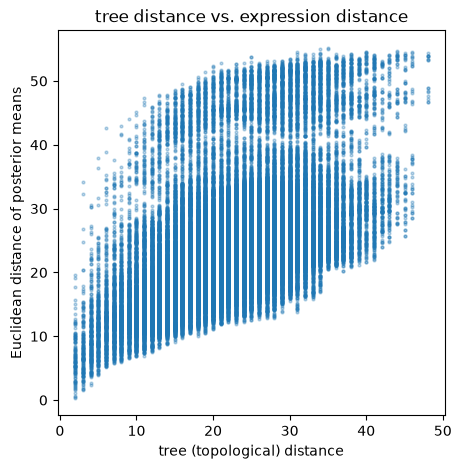

In [15]:
if adata_brain is not None:

    def cophenetic_matrix_b(leaf_names, children, root, name_to_vert):
        """Pairwise topological (path-length) distance matrix between `leaf_names`, root-independent."""
        paths = leaf_paths_from_root(children, root)
        verts = [name_to_vert[name] for name in leaf_names]
        n = len(verts)
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = pairwise_topo_distance(verts[i], verts[j], paths)
        return D

    leaf_names_order = list(leaf_node_post.obs_names)
    tree_dist = squareform(cophenetic_matrix_b(leaf_names_order, children_b, root_b, vert_of_name))
    expr_dist = pdist(leaf_node_post.X)

    fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
    ax.scatter(tree_dist, expr_dist, s=4, alpha=0.3)
    ax.set_xlabel("tree (topological) distance")
    ax.set_ylabel("Euclidean distance of posterior means")
    ax.set_title("tree distance vs. expression distance")
    plt.show()

## 4. A second real dataset: intestinal-organoid EEC differentiation (Sanity-processed)

A VASA-seq atlas of enteroendocrine-cell (EEC) differentiation in human intestinal organoids, from
the lab's EEC fate project (1,373 cells x 60,666 genes, `obs["cell_type_initial"]` with 11 EEC
subtypes). We subsample 482 cells stratified by `cell_type_initial` (fixed seed,
`docs/notebooks/prepare_organoid_data.py`; about 45 cells are requested per type, so small types
such as K cells (36 total) and I cells / SMOC2+ cells (43 each) are taken whole), round the raw
counts to integers (`np.rint`, clipped at 0) since the source counts are not all integers (about
1.19% of all count entries, 9.41% of nonzero entries, changed by rounding — likely multi-mapping
splits), keep genes detected in >=10 sampled cells (22,981 genes), and preprocess with *Sanity*
before handing the result to *Bonsai*.

`.X` has no spike-in rows (spike-ins are tracked in `obs["nCount_spike_ins"]`), and the prep
script drops only gene names matching `^ERCC-\d{5}$`, of which this dataset has none.

**Preprocessing (outside this notebook, see `prepare_organoid_data.py`)**

```bash
python docs/notebooks/prepare_organoid_data.py <vasa_eec_atlas.h5ad> <out_dir> --n-cells 500 \
    --seed 0 --strata-cols cell_type_initial --counts-source X --round
```

This writes `counts.tsv` (genes x cells, tab-separated, as *Sanity*'s `-f` flag expects) and
`cell_meta.csv` (the sampled cells' annotations, for plotting here). *Sanity* is then run once,
with the flags the package README requires (`-e 1 -v_m MAP`):

```bash
Sanity -f counts.tsv -d sanity_out -n <threads> -e 1 -v_m MAP
```

This took about 153s for 482 cells x 22,981 genes on a shared 2-core node (measured from the first
to the last timestamp in `sanity_out`'s run log); 4,668 of the 22,981 genes survived *Bonsai*'s
z-score filter (`var["bonsai_used"]`, printed below). As in the brain-organoid section, the
*Bonsai* reconstruction below uses a reduced random-tree search budget (`nnn_n_randommoves=20,
nnn_n_randomtrees=2`, vs. the function defaults of 1000/10) purely as a computational shortcut to
keep runtime reasonable on such a node — see the runtime table at the end for exact numbers; this
does not change what the algorithm optimises. As in §1, *Bonsai*'s root is a display convention and
carries no biological meaning by itself.


In [16]:
if not EEC_DIR.exists():
    print(f"EEC-organoid inputs not found at {relative(EEC_DIR)}; skipping this section.")
    adata_eec = None
else:
    cached_h5ad = EEC_DIR / "adata_bonsai.h5ad"
    workdir = EEC_DIR / "bonsai_workdir"
    if not RERUN and cached_h5ad.exists():
        adata_eec = ad.read_h5ad(cached_h5ad)
        # See the equivalent comment in §3: keep whichever workdir subfolder name the cached run
        # actually used.
        cached_workdir_name = Path(adata_eec.uns["bonsai"]["workdir"]).name
        workdir = EEC_DIR / cached_workdir_name
        assert workdir.exists(), f"cached workdir {workdir} is missing"
        adata_eec.uns["bonsai"]["workdir"] = str(workdir)
        time_eec = adata_eec.uns.get("bonsai_tour_seconds")
        print(f"loaded cached reconstruction: {adata_eec}")
    else:
        adata_eec = bonsai.pp.read_sanity(EEC_DIR / "sanity_out")
        cell_meta = pd.read_csv(EEC_DIR / "cell_meta.csv", index_col=0)
        adata_eec.obs = adata_eec.obs.join(cell_meta)
        if workdir.exists():
            # reconstruct() refuses a non-empty pre-existing workdir; a rerun gets a fresh one.
            workdir = EEC_DIR / f"bonsai_workdir_{int(time.time())}"
        t0 = time.time()
        reconstruct_quietly(
            adata_eec,
            nnn_n_randommoves=20,
            nnn_n_randomtrees=2,
            workdir=workdir,
            keep_workdir=True,
            verbose=False,
        )
        time_eec = time.time() - t0
        adata_eec.uns["bonsai_tour_seconds"] = time_eec
        print(f"reconstructed in {time_eec:.1f}s")
        adata_eec.write_h5ad(cached_h5ad)
    print(adata_eec)
    print(f"{adata_eec.var['bonsai_used'].sum()} genes used of {adata_eec.n_vars}")

loaded cached reconstruction: AnnData object with n_obs × n_vars = 482 × 22981
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spike_ins', 'nFeature_spike_ins', 'Library', 'percent.mt', 'percent.rb', 'barcode', 'wellID', 'ERCC_well', 'RNA_snn_res.0.5', 'Cluster', 'Well.ID', 'DT', 'Number', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.1', 'seurat_clusters', 'cell_type_initial', 'bonsai_node'
    var: 'bonsai_prior_var', 'bonsai_mu', 'bonsai_used'
    uns: 'bonsai', 'bonsai_input', 'bonsai_tour_seconds'
    layers: 'bonsai_mean', 'bonsai_sd'
AnnData object with n_obs × n_vars = 482 × 22981
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spike_ins', 'nFeature_spike_ins', 'Library', 'percent.mt', 'percent.rb', 'barcode', 'wellID', 'ERCC_well', 'RNA_snn_res.0.5', 'Cluster', 'Well.ID', 'DT', 'Number', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.1', 'seurat_clusters', 'cell_type_initial', 'bonsai_node'
    var: 'bonsai_prior_var', 'bonsai_mu', 'bonsai_used'
    uns: 'bo

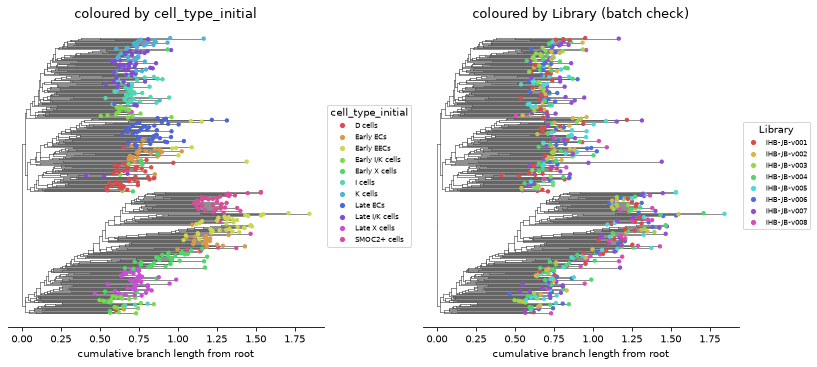

In [17]:
if adata_eec is not None:
    import colorsys

    from matplotlib.colors import ListedColormap

    def categorical_palette(n):
        """`n` evenly spaced, equal-saturation hues as a size-`n` `ListedColormap`.

        `plot_tree` builds its per-category colour via `palette(i / (n_cats - 1))`; for a
        `ListedColormap` with exactly `n_cats` colours this samples colour `i` exactly (no
        clustering within one colormap's colour "families" and no fixed-palette greys, since
        every colour here has the same nonzero saturation).
        """
        return ListedColormap([colorsys.hsv_to_rgb(i / n, 0.65, 0.85) for i in range(n)])

    edges_e, nodes_e = adata_eec.uns["bonsai"]["edges"], adata_eec.uns["bonsai"]["nodes"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=75, facecolor="white")
    celltype_colors = dict(zip(adata_eec.obs_names, adata_eec.obs["cell_type_initial"].astype(str), strict=True))
    plot_tree(
        edges_e,
        nodes_e,
        leaf_color=celltype_colors,
        cmap=categorical_palette(adata_eec.obs["cell_type_initial"].nunique()),
        ax=axes[0],
        legend_title="cell_type_initial",
    )
    axes[0].set_title("coloured by cell_type_initial")
    library_colors = dict(zip(adata_eec.obs_names, adata_eec.obs["Library"].astype(str), strict=True))
    plot_tree(
        edges_e,
        nodes_e,
        leaf_color=library_colors,
        cmap=categorical_palette(adata_eec.obs["Library"].nunique()),
        ax=axes[1],
        legend_title="Library",
    )
    axes[1].set_title("coloured by Library (batch check)")
    fig.tight_layout()
    plt.show()

### Gene painting

As in §3, `bonsai.tl.node_posteriors` gives posterior means per used gene per tree node. The
candidate panel (filtered to genes in `var["bonsai_used"]`, first 6 hits) shows CHGA and CHGB
(pan-endocrine granule markers), NEUROG3 and NEUROD1 (EEC-fate transcription factors), and PAX4 and
ARX (subtype-specifying transcription factors).


markers shown (present in bonsai_used): ['CHGA', 'CHGB', 'NEUROG3', 'NEUROD1', 'PAX4', 'ARX']


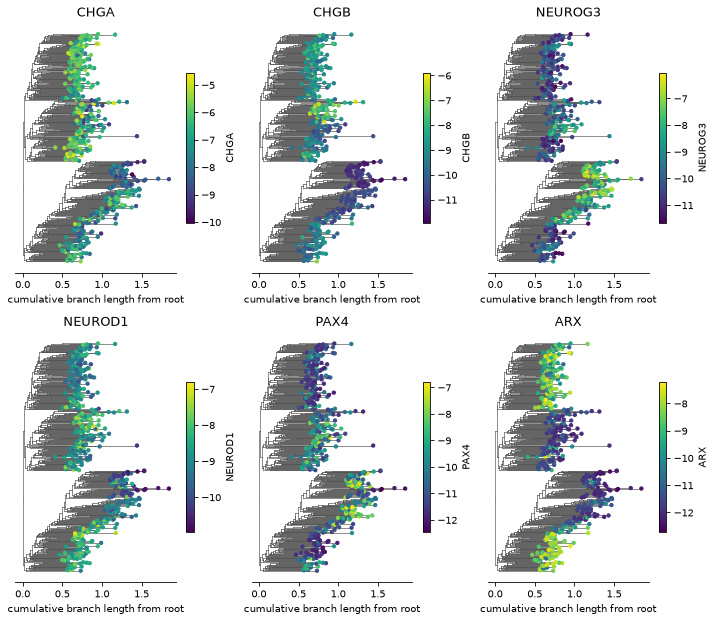

In [18]:
if adata_eec is not None:
    node_post_e = bonsai.tl.node_posteriors(adata_eec)
    candidate_markers_e = [
        "CHGA",
        "CHGB",
        "NEUROG3",
        "NEUROD1",
        "PAX4",
        "ARX",
        "TPH1",
        "GCG",
        "PYY",
        "GIP",
        "CCK",
        "SST",
        "MLN",
        "GHRL",
        "SMOC2",
        "LGR5",
        "MKI67",
    ]
    markers_e = [g for g in candidate_markers_e if g in node_post_e.var_names][:6]
    print("markers shown (present in bonsai_used):", markers_e)

    leaf_vert_e = {
        row["name"]: row["vertInd"] for _, row in nodes_e.iterrows() if row["name"] in set(adata_eec.obs_names)
    }
    ncols_e = min(3, len(markers_e))
    nrows_e = -(-len(markers_e) // ncols_e)  # ceil
    fig, axes = plt.subplots(nrows_e, ncols_e, figsize=(3.2 * ncols_e, 4.2 * nrows_e), dpi=75, facecolor="white")
    for ax, gene in zip(np.atleast_1d(axes).ravel(), markers_e, strict=True):
        vals_by_vert = dict(zip(node_post_e.obs["vertInd"], node_post_e[:, gene].X.ravel(), strict=True))
        leaf_color = {name: vals_by_vert[v] for name, v in leaf_vert_e.items()}
        plot_tree(edges_e, nodes_e, leaf_color=leaf_color, continuous=True, ax=ax, legend_title=gene)
        ax.set_title(gene)
    for ax in np.atleast_1d(axes).ravel()[len(markers_e) :]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

### Heatmap of ~25 informative genes (cells in tree-leaf order)

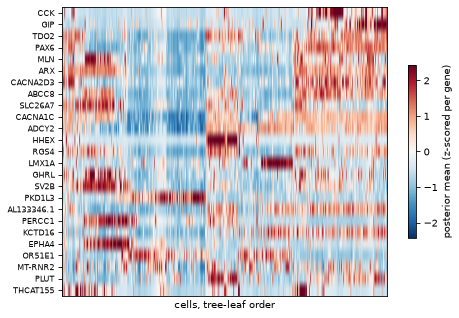

In [19]:
if adata_eec is not None:
    gene_var_e = node_post_e.X.var(axis=0)
    top_genes_e = node_post_e.var_names[np.argsort(gene_var_e)[::-1][:25]]

    children_e, root_e = tree_topology(edges_e, nodes_e)
    sizes_e = subtree_sizes(children_e, root_e)
    ordered_vert_e = [v for v in ladderised_leaf_order(root_e, children_e, sizes_e) if v in set(leaf_vert_e.values())]
    vert_to_name_e = nodes_e.set_index("vertInd")["name"]
    ordered_names_e = [vert_to_name_e[v] for v in ordered_vert_e]

    leaf_node_post_e = node_post_e[node_post_e.obs["vertInd"].isin(leaf_vert_e.values())]
    leaf_node_post_e = leaf_node_post_e[[n for n in ordered_names_e if n in leaf_node_post_e.obs_names]]
    raw_e = leaf_node_post_e[:, top_genes_e].X.T
    mat_e = (raw_e - raw_e.mean(axis=1, keepdims=True)) / raw_e.std(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(7, 5), dpi=75, facecolor="white")
    clip = np.percentile(np.abs(mat_e), 98)
    im = ax.imshow(mat_e, aspect="auto", cmap="RdBu_r", vmin=-clip, vmax=clip)
    ax.set_yticks(range(len(top_genes_e)))
    ax.set_yticklabels(top_genes_e, fontsize=8)
    ax.set_xlabel("cells, tree-leaf order")
    ax.set_xticks([])
    plt.colorbar(im, ax=ax, shrink=0.6, label="posterior mean (z-scored per gene)")
    plt.show()

### Tree distance vs. expression distance (EEC organoid)

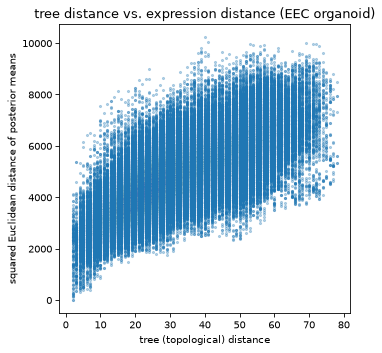

In [20]:
if adata_eec is not None:
    leaf_names_order_e = list(leaf_node_post_e.obs_names)
    vert_of_name_e = nodes_e.set_index("name")["vertInd"]
    tree_dist_e = squareform(cophenetic_matrix_b(leaf_names_order_e, children_e, root_e, vert_of_name_e))
    expr_dist_e = pdist(leaf_node_post_e.X, metric="sqeuclidean")

    fig, ax = plt.subplots(figsize=(5, 5), dpi=75, facecolor="white")
    ax.scatter(tree_dist_e, expr_dist_e, s=4, alpha=0.3)
    ax.set_xlabel("tree (topological) distance")
    ax.set_ylabel("squared Euclidean distance of posterior means")
    ax.set_title("tree distance vs. expression distance (EEC organoid)")
    plt.show()

## 5. A third real dataset: CRISPR-perturbation atlas, control cells only (Sanity-processed)

A large (~1M-cell, 13 GB) CRISPR knockout screen in human intestinal organoids, from the lab's EEC
fate project (`obs["annotation"]` with 13 lineage states: stem/TA/cycling-TA, enterocytes, goblet,
Paneth, EEC progenitors, and differentiated EEC subtypes). To get a Bonsai-sized input without
loading the 1,026,005 x 46,388 matrix, `docs/notebooks/prepare_perturb_ctrl_data.py` reads only
`obs` (small) via `h5py`, selects `obs["genetic_perturbation_strategy"] == "control"` (89,382 of
the 1,026,005 cells), and then reads *only* the picked rows of `raw/X` — a CSR group — by slicing
`indptr` for each picked row and reading just that row's `data`/`indices` range directly from disk;
the full matrix is never loaded or densified. The raw gene index (`raw/var/feature_id`) holds
Ensembl gene ids (`ENSG...`); gene symbols come from `raw/var/gene_name` (unique, no collisions),
which is what the prep script uses.

We subsample 598 control cells stratified by `annotation` (fixed seed; about 46 cells are requested
per type, so the three smallest types — D Cells (218 available), Paneth Cells (276) and K Cells
(493) — are closest to being under-filled, though all 13 types reached their 46-cell quota here),
verify the sampled `raw.X` entries are integer-valued, keep genes detected in >=10 sampled cells
(14,014 genes), and preprocess with *Sanity* before handing the result to *Bonsai*.

**Preprocessing (outside this notebook, see `prepare_perturb_ctrl_data.py`)**

```bash
python docs/notebooks/prepare_perturb_ctrl_data.py <perturb_atlas.h5ad> <out_dir> --n-cells 600 --seed 0
```

This writes `counts.tsv` (genes x cells, tab-separated) and `cell_meta.csv` (annotation, batch,
sample for the sampled cells). *Sanity* is then run once, with the flags the package README
requires (`-e 1 -v_m MAP`):

```bash
Sanity -f counts.tsv -d sanity_out -n <threads> -e 1 -v_m MAP
```

This took about 285s for 598 cells x 14,014 genes on a shared 2-core node (measured from the first
to the last timestamp in `sanity_out`'s run log). As in §3-4, the *Bonsai* reconstruction below
uses a reduced random-tree search budget (`nnn_n_randommoves=20, nnn_n_randomtrees=2`) purely as a
computational shortcut — see the runtime table at the end for exact numbers. As in §1, *Bonsai*'s
root is a display convention and carries no biological meaning by itself.


In [21]:
if not PERTURB_DIR.exists():
    print(f"perturbation-atlas inputs not found at {relative(PERTURB_DIR)}; skipping this section.")
    adata_perturb = None
else:
    cached_h5ad = PERTURB_DIR / "adata_bonsai.h5ad"
    workdir = PERTURB_DIR / "bonsai_workdir"
    if not RERUN and cached_h5ad.exists():
        adata_perturb = ad.read_h5ad(cached_h5ad)
        # See the equivalent comment in §3: keep whichever workdir subfolder name the cached run
        # actually used.
        cached_workdir_name = Path(adata_perturb.uns["bonsai"]["workdir"]).name
        workdir = PERTURB_DIR / cached_workdir_name
        assert workdir.exists(), f"cached workdir {workdir} is missing"
        adata_perturb.uns["bonsai"]["workdir"] = str(workdir)
        time_perturb = adata_perturb.uns.get("bonsai_tour_seconds")
        print(f"loaded cached reconstruction: {adata_perturb}")
    else:
        adata_perturb = bonsai.pp.read_sanity(PERTURB_DIR / "sanity_out")
        cell_meta = pd.read_csv(PERTURB_DIR / "cell_meta.csv", index_col=0)
        adata_perturb.obs = adata_perturb.obs.join(cell_meta)
        if workdir.exists():
            # reconstruct() refuses a non-empty pre-existing workdir; a rerun gets a fresh one.
            workdir = PERTURB_DIR / f"bonsai_workdir_{int(time.time())}"
        t0 = time.time()
        reconstruct_quietly(
            adata_perturb,
            nnn_n_randommoves=20,
            nnn_n_randomtrees=2,
            workdir=workdir,
            keep_workdir=True,
            verbose=False,
        )
        time_perturb = time.time() - t0
        adata_perturb.uns["bonsai_tour_seconds"] = time_perturb
        print(f"reconstructed in {time_perturb:.1f}s")
        adata_perturb.write_h5ad(cached_h5ad)
    print(adata_perturb)
    print(f"{adata_perturb.var['bonsai_used'].sum()} genes used of {adata_perturb.n_vars}")

loaded cached reconstruction: AnnData object with n_obs × n_vars = 598 × 14014
    obs: 'annotation', 'batch', 'sample', 'bonsai_node'
    var: 'bonsai_prior_var', 'bonsai_mu', 'bonsai_used'
    uns: 'bonsai', 'bonsai_input', 'bonsai_tour_seconds'
    layers: 'bonsai_mean', 'bonsai_sd'
AnnData object with n_obs × n_vars = 598 × 14014
    obs: 'annotation', 'batch', 'sample', 'bonsai_node'
    var: 'bonsai_prior_var', 'bonsai_mu', 'bonsai_used'
    uns: 'bonsai', 'bonsai_input', 'bonsai_tour_seconds'
    layers: 'bonsai_mean', 'bonsai_sd'
281 genes used of 14014


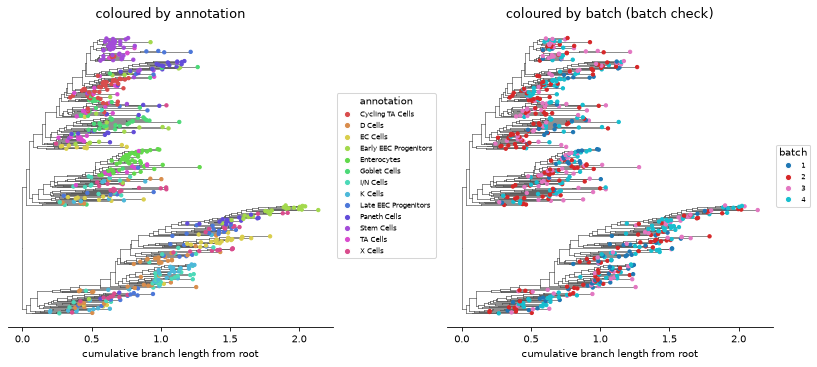

In [22]:
if adata_perturb is not None:
    edges_p, nodes_p = adata_perturb.uns["bonsai"]["edges"], adata_perturb.uns["bonsai"]["nodes"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=75, facecolor="white")
    annotation_colors = dict(zip(adata_perturb.obs_names, adata_perturb.obs["annotation"].astype(str), strict=True))
    plot_tree(
        edges_p,
        nodes_p,
        leaf_color=annotation_colors,
        cmap=categorical_palette(adata_perturb.obs["annotation"].nunique()),
        ax=axes[0],
        legend_title="annotation",
    )
    axes[0].set_title("coloured by annotation")
    batch_colors = dict(zip(adata_perturb.obs_names, adata_perturb.obs["batch"].astype(str), strict=True))
    plot_tree(edges_p, nodes_p, leaf_color=batch_colors, ax=axes[1], legend_title="batch")
    axes[1].set_title("coloured by batch (batch check)")
    fig.tight_layout()
    plt.show()

### Gene painting

As in §3-4, `bonsai.tl.node_posteriors` gives posterior means per used gene per tree node. The
candidate panel (filtered to genes in `var["bonsai_used"]`, first 6 hits) shows LGR5 and OLFM4
(stem-cell markers), MKI67 (cycling), APOA4 (enterocyte), MUC2 (goblet), and DEFA5 (Paneth). FABP2
(enterocyte), DEFA6/LYZ (Paneth) and the EEC markers CHGA/NEUROG3 were also candidates but either
did not survive the z-score filter or fell past the 6-panel cutoff in this subsample.


markers shown (present in bonsai_used): ['LGR5', 'OLFM4', 'MKI67', 'APOA4', 'MUC2', 'DEFA5']


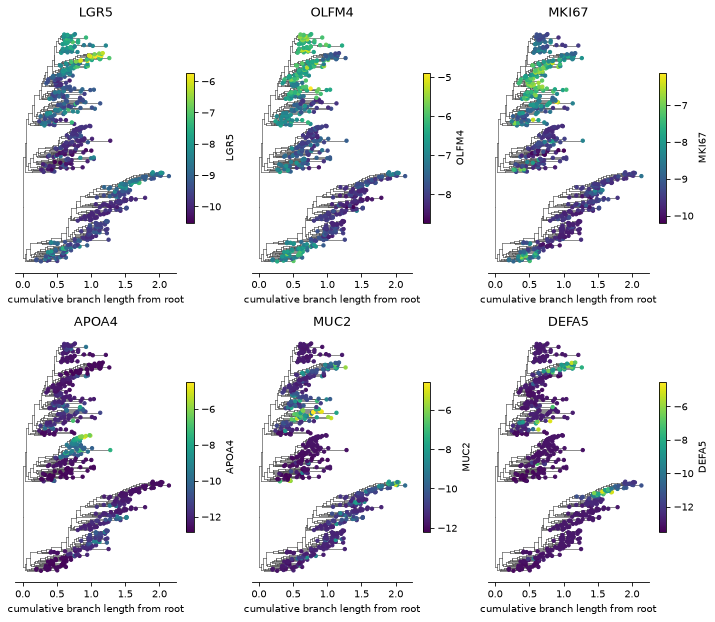

In [23]:
if adata_perturb is not None:
    node_post_p = bonsai.tl.node_posteriors(adata_perturb)
    candidate_markers_p = [
        "LGR5",
        "OLFM4",
        "MKI67",
        "FABP2",
        "APOA4",
        "MUC2",
        "DEFA5",
        "DEFA6",
        "LYZ",
        "CHGA",
        "NEUROG3",
    ]
    markers_p = [g for g in candidate_markers_p if g in node_post_p.var_names][:6]
    print("markers shown (present in bonsai_used):", markers_p)

    leaf_vert_p = {
        row["name"]: row["vertInd"] for _, row in nodes_p.iterrows() if row["name"] in set(adata_perturb.obs_names)
    }
    ncols_p = min(3, len(markers_p))
    nrows_p = -(-len(markers_p) // ncols_p)  # ceil
    fig, axes = plt.subplots(nrows_p, ncols_p, figsize=(3.2 * ncols_p, 4.2 * nrows_p), dpi=75, facecolor="white")
    for ax, gene in zip(np.atleast_1d(axes).ravel(), markers_p, strict=True):
        vals_by_vert = dict(zip(node_post_p.obs["vertInd"], node_post_p[:, gene].X.ravel(), strict=True))
        leaf_color = {name: vals_by_vert[v] for name, v in leaf_vert_p.items()}
        plot_tree(edges_p, nodes_p, leaf_color=leaf_color, continuous=True, ax=ax, legend_title=gene)
        ax.set_title(gene)
    for ax in np.atleast_1d(axes).ravel()[len(markers_p) :]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

### Heatmap of ~25 informative genes (cells in tree-leaf order)

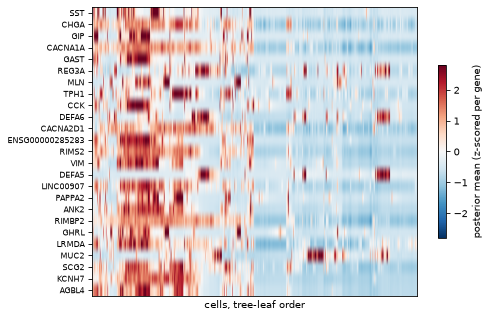

In [24]:
if adata_perturb is not None:
    gene_var_p = node_post_p.X.var(axis=0)
    top_genes_p = node_post_p.var_names[np.argsort(gene_var_p)[::-1][:25]]

    children_p, root_p = tree_topology(edges_p, nodes_p)
    sizes_p = subtree_sizes(children_p, root_p)
    ordered_vert_p = [v for v in ladderised_leaf_order(root_p, children_p, sizes_p) if v in set(leaf_vert_p.values())]
    vert_to_name_p = nodes_p.set_index("vertInd")["name"]
    ordered_names_p = [vert_to_name_p[v] for v in ordered_vert_p]

    leaf_node_post_p = node_post_p[node_post_p.obs["vertInd"].isin(leaf_vert_p.values())]
    leaf_node_post_p = leaf_node_post_p[[n for n in ordered_names_p if n in leaf_node_post_p.obs_names]]
    raw_p = leaf_node_post_p[:, top_genes_p].X.T
    mat_p = (raw_p - raw_p.mean(axis=1, keepdims=True)) / raw_p.std(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(7, 5), dpi=75, facecolor="white")
    clip = np.percentile(np.abs(mat_p), 98)
    im = ax.imshow(mat_p, aspect="auto", cmap="RdBu_r", vmin=-clip, vmax=clip)
    ax.set_yticks(range(len(top_genes_p)))
    ax.set_yticklabels(top_genes_p, fontsize=8)
    ax.set_xlabel("cells, tree-leaf order")
    ax.set_xticks([])
    plt.colorbar(im, ax=ax, shrink=0.6, label="posterior mean (z-scored per gene)")
    plt.show()

### Tree distance vs. expression distance (perturbation-atlas controls)

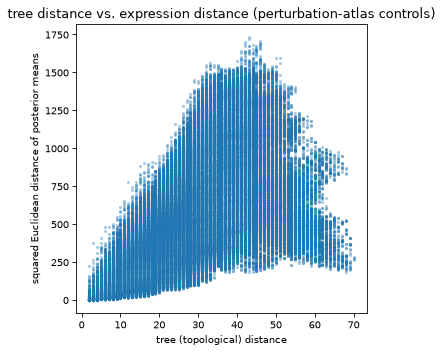

In [25]:
if adata_perturb is not None:
    leaf_names_order_p = list(leaf_node_post_p.obs_names)
    vert_of_name_p = nodes_p.set_index("name")["vertInd"]
    tree_dist_p = squareform(cophenetic_matrix_b(leaf_names_order_p, children_p, root_p, vert_of_name_p))
    expr_dist_p = pdist(leaf_node_post_p.X, metric="sqeuclidean")

    fig, ax = plt.subplots(figsize=(5, 5), dpi=75, facecolor="white")
    ax.scatter(tree_dist_p, expr_dist_p, s=4, alpha=0.3)
    ax.set_xlabel("tree (topological) distance")
    ax.set_ylabel("squared Euclidean distance of posterior means")
    ax.set_title("tree distance vs. expression distance (perturbation-atlas controls)")
    plt.show()

## Saving and reloading

`uns["bonsai"]` round-trips through `adata.write_h5ad` / `anndata.read_h5ad`.


In [26]:
import tempfile

target = adata_brain if adata_brain is not None else adata_sim
with tempfile.TemporaryDirectory() as tmp_dir:
    tmp_path = Path(tmp_dir) / "_tour_roundtrip_check.h5ad"
    target.write_h5ad(tmp_path)
    reloaded = ad.read_h5ad(tmp_path)
print("newick survives round-trip:", reloaded.uns["bonsai"]["newick"] == target.uns["bonsai"]["newick"])
print("loglik survives round-trip:", reloaded.uns["bonsai"]["loglik"] == target.uns["bonsai"]["loglik"])

newick survives round-trip: True
loglik survives round-trip: True


## Runtime summary

Indicative only — a shared, loaded node with few cores gives timings that are not reproducible
across machines or runs.


In [27]:
rows = [
    {
        "dataset": "64-cell simulated binary tree",
        "cells": adata_64.n_obs,
        "genes_used": int(adata_64.var["bonsai_used"].sum()),
        "seconds": round(time_64, 1),
    },
    {
        "dataset": "~300-cell in-notebook simulator",
        "cells": adata_sim.n_obs,
        "genes_used": int(adata_sim.var["bonsai_used"].sum()),
        "seconds": round(time_sim, 1),
    },
]
if adata_brain is not None:
    rows.append(
        {
            "dataset": "brain organoid (subsampled, Sanity)",
            "cells": adata_brain.n_obs,
            "genes_used": int(adata_brain.var["bonsai_used"].sum()),
            "seconds": round(time_brain, 1) if time_brain is not None else float("nan"),
        }
    )
if adata_eec is not None:
    rows.append(
        {
            "dataset": "EEC organoid (subsampled, Sanity)",
            "cells": adata_eec.n_obs,
            "genes_used": int(adata_eec.var["bonsai_used"].sum()),
            "seconds": round(time_eec, 1) if time_eec is not None else float("nan"),
        }
    )
if adata_perturb is not None:
    rows.append(
        {
            "dataset": "perturbation-atlas controls (subsampled, Sanity)",
            "cells": adata_perturb.n_obs,
            "genes_used": int(adata_perturb.var["bonsai_used"].sum()),
            "seconds": round(time_perturb, 1) if time_perturb is not None else float("nan"),
        }
    )
pd.DataFrame(rows)

,dataset,cells,genes_used,seconds
0,64-cell simulated binary tree,64,1131,52.3
1,~300-cell in-notebook simulator,300,500,320.8
2,"brain organoid (subsampled, Sanity)",387,626,263.1
3,"EEC organoid (subsampled, Sanity)",482,4668,3279.5
4,"perturbation-atlas controls (subsampled, Sanity)",598,281,1059.4
